# Consulta Prévia contracts

Contracts whose `tipo_procedimento` is a Consulta Prévia variant: `Consulta Prévia` (67 826), `Consulta Prévia Simplificada` (1 218) and the Lei 30/2021 art. 7.º variant (20).

**Rule:** `tipo_procedimento` lowercased and accent-folded `.str.starts_with("consulta previa")`. Reference: **69,064 rows** on the current parquet.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from base_gov.contracts import load_contracts
from base_gov.entities import (
    canonical_names,
    entity_key,
    explode_entities,
)
from base_gov.stats import MIN_VALUE, value_impact

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
contracts_all = load_contracts(DATA / "contracts.parquet").rename(
    {"TipoCriterioAdjudicacao": "tipo_criterio_adjudicacao"}
)
print(f"rows={contracts_all.height:,}  cols={contracts_all.width}")
# Disregard contracts flagged is_below_min_value (|preco_contratual| < MIN_VALUE, €); contracts_all keeps them for before/after comparisons.
contracts = contracts_all.filter(~pl.col("is_below_min_value"))
print(f"disregarded {contracts_all.height - contracts.height:,} contracts with |preco_contratual| < €{MIN_VALUE:g} "
      f"({(contracts_all.height - contracts.height) / contracts_all.height:.2%}); kept {contracts.height:,}")
print(f"valor_por_dia defined for {contracts['valor_por_dia'].is_not_null().mean():.1%} of kept contracts "
      f"(needs 1 <= prazo_execucao <= 3650 days)")
contracts.head()
print(contracts["adjudicante_key_source"].value_counts(sort=True))

rows=643,548  cols=31
disregarded 2,307 contracts with |preco_contratual| < €10 (0.36%); kept 641,241
valor_por_dia defined for 99.0% of kept contracts (needs 1 <= prazo_execucao <= 3650 days)
shape: (2, 2)
┌────────────────────────┬────────┐
│ adjudicante_key_source ┆ count  │
│ ---                    ┆ ---    │
│ str                    ┆ u32    │
╞════════════════════════╪════════╡
│ nipc                   ┆ 640989 │
│ name                   ┆ 252    │
└────────────────────────┴────────┘


In [3]:
CPREV_EXPR = (
    pl.col("tipo_procedimento")
    .str.to_lowercase()
    .str.replace_all("ú", "u")
    .str.replace_all("é", "e")
    .str.starts_with("consulta previa")
)
contracts["tipo_procedimento"].value_counts(sort=True)

tipo_procedimento,count
str,u32
"""Ajuste Direto Regime Geral""",290532
"""Consulta Prévia""",110004
"""Concurso público""",98870
"""Ao abrigo de acordo-quadro (ar…",83048
"""Contratação excluída II""",34029
"""Ao abrigo de acordo-quadro (ar…",16201
"""Setores especiais – isenção pa…",3300
"""Ajuste direto simplificado ao …",1784
"""Consulta Prévia Simplificada""",1652


In [4]:
proc = contracts.filter(CPREV_EXPR)
print(f"Consulta Prévia rows: {proc.height:,}  share by count: {proc.height / contracts.height:.1%}  "
      f"share by value: {proc['preco_contratual'].sum() / contracts['preco_contratual'].sum():.1%}")
variants = proc["tipo_procedimento"].value_counts(sort=True)
display(variants)
assert variants["count"].sum() == proc.height and proc.height < contracts.height
variants

n_before = contracts_all.filter(CPREV_EXPR).height
n_after = proc.height
assert n_after <= n_before
print(f"{n_before:,} before the €{MIN_VALUE:g} flag, {n_after:,} after "
      f"({n_before - n_after:,} flagged below the threshold)")

Consulta Prévia rows: 111,686  share by count: 17.4%  share by value: 7.0%


tipo_procedimento,count
str,u32
"""Consulta Prévia""",110004
"""Consulta Prévia Simplificada""",1652
"""Consulta prévia ao abrigo do a…",30


111,876 before the €10 flag, 111,686 after (190 flagged below the threshold)


In [5]:
# Effect of disregarding contracts with |value| below €10 on Consulta Prévia.
before = contracts_all.filter(CPREV_EXPR)
display(value_impact(before, proc))

metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",111876.0,111686.0,-190.0,-0.17
"""mean_value""",35508.405506,35568.811437,60.405931,0.17
"""median_value""",22500.0,22500.0,0.0,0.0
"""total_value""",3.9725e9,3.9725e9,-100.23,-0.0


prazo_execucao outside 1..3650 days (excluded from value/day): 360 of 111,686


prazo_p10,prazo_p25,prazo_p50,prazo_p75,prazo_p90,eur_dia_p10,eur_dia_p25,eur_dia_p50,eur_dia_p75,eur_dia_p90
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
20.0,45.0,180.0,365.0,730.0,14.91,39.11,123.82,560.59,1548.94


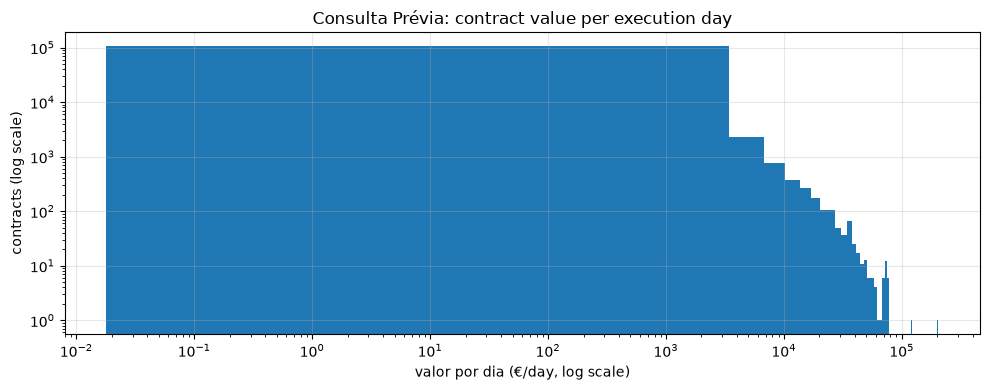

In [6]:
# Execution time (prazo_execucao, days) and value per day. valor_por_dia is null outside 1..3650 days.
d = proc
print(f"prazo_execucao outside 1..3650 days (excluded from value/day): {d['valor_por_dia'].is_null().sum():,} of {d.height:,}")
display(d.select(
    *[pl.col("prazo_execucao").quantile(q).alias(f"prazo_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
    *[pl.col("valor_por_dia").quantile(q).round(2).alias(f"eur_dia_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
))
vd = d["valor_por_dia"].drop_nulls()
fig, ax = plt.subplots()
ax.hist(vd.filter(vd > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("valor por dia (€/day, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Consulta Prévia: contract value per execution day")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# By duration bucket: how price and price/day move with the contract length.
buckets = (
    proc.filter(pl.col("valor_por_dia").is_not_null())
    .with_columns(
        pl.when(pl.col("prazo_execucao") <= 30).then(pl.lit("1-30 d"))
        .when(pl.col("prazo_execucao") <= 90).then(pl.lit("31-90 d"))
        .when(pl.col("prazo_execucao") <= 365).then(pl.lit("91-365 d"))
        .otherwise(pl.lit("366-3650 d")).alias("duracao")
    )
    .group_by("duracao")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").median().alias("median_value"),
        pl.col("valor_por_dia").median().round(2).alias("median_eur_per_day"),
        pl.col("preco_contratual").sum().round(0).alias("total_value"),
    )
    .sort("median_value")
)
buckets

duracao,n_contracts,median_value,median_eur_per_day,total_value
str,u32,f64,f64,f64
"""91-365 d""",50146,17684.605,62.56,1.5538e9
"""1-30 d""",23303,18699.0,1014.29,6.21952096e8
"""31-90 d""",20641,31560.0,511.98,9.08621553e8
"""366-3650 d""",17236,35170.475,42.57,8.82940254e8


In [8]:
# One row per (contract, awardee), keyed by NIPC; name similarity only for the "-" (no NIF) sentinel.
awardees = entity_key(explode_entities(proc, "adjudicatarios", prefix="adjudicatarios"), prefix="adjudicatarios")
print(awardees["adjudicatarios_status"].value_counts(sort=True))
print(awardees["adjudicatarios_key_source"].value_counts(sort=True))

shape: (2, 2)
┌───────────────────────┬────────┐
│ adjudicatarios_status ┆ count  │
│ ---                   ┆ ---    │
│ str                   ┆ u32    │
╞═══════════════════════╪════════╡
│ YES                   ┆ 101016 │
│ NO_NIF                ┆ 10897  │
└───────────────────────┴────────┘
shape: (2, 2)
┌───────────────────────────┬────────┐
│ adjudicatarios_key_source ┆ count  │
│ ---                       ┆ ---    │
│ str                       ┆ u32    │
╞═══════════════════════════╪════════╡
│ nipc                      ┆ 101016 │
│ name                      ┆ 10897  │
└───────────────────────────┴────────┘


In [9]:
by_adjudicante = (
    proc.group_by("adjudicante_key")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().round(2).alias("total_value"))
    .join(canonical_names(proc, prefix="adjudicante"), on="adjudicante_key", how="left")
)
print("Top 20 adjudicantes by Consulta Prévia count:")
display(by_adjudicante.sort("n_contracts", descending=True).head(20))
print("\nTop 20 adjudicantes by Consulta Prévia value:")
display(by_adjudicante.sort("total_value", descending=True).head(20))

Top 20 adjudicantes by Consulta Prévia count:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""511228848""",1554,2.5682e7,"""Serviço de Saúde da Região Aut…"
"""508481287""",953,1.4585e7,"""Unidade Local de Saúde de Sant…"
"""510103448""",841,1.0720e7,"""Unidade Local de Saúde de Coim…"
"""500051062""",684,1.1140e7,"""Município de Sintra"""
"""501442600""",617,1.3298e7,"""Instituto do Emprego e da Form…"
"""501413197""",607,1.7930e7,"""Universidade do Porto"""
"""508080142""",603,1.1107e7,"""Unidade Local de Saúde de São …"
"""505804786""",590,2.3952e7,"""Município de Vila do Conde"""
"""506663264""",575,2.6983e7,"""Município de Vila Nova de Fama…"



Top 20 adjudicantes by Consulta Prévia value:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""503933813""",285,1.7820e8,"""Infraestruturas de Portugal, S…"
"""506614913""",493,3.5203e7,"""Município de Vila Franca de Xi…"
"""505187531""",295,3.5109e7,"""Município de Cascais"""
"""506173968""",492,3.1219e7,"""Município do Seixal"""
"""500051070""",514,2.7119e7,"""Município de Lisboa"""
"""506663264""",575,2.6983e7,"""Município de Vila Nova de Fama…"
"""511010435""",165,2.6646e7,"""EEM - Empresa de Electricidade…"
"""500745943""",500,2.5943e7,"""Município de Oeiras"""
"""511228848""",1554,2.5682e7,"""Serviço de Saúde da Região Aut…"


In [10]:
# One row per (contract, awardee). Contract value is not split between awardees: for multi-awardee
# contracts the value is counted in full for each awardee (state this when reading the table).
awardees = awardees.join(proc.select("idcontrato", "preco_contratual"), on="idcontrato", how="left")
by_awardee = (
    awardees.group_by("adjudicatarios_key")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").sum().round(2).alias("total_value"),
        pl.col("adjudicatarios_key_source").first().alias("key_source"),
    )
    .join(canonical_names(awardees, prefix="adjudicatarios"), on="adjudicatarios_key", how="left")
)
print("Top 20 adjudicatarios by count (key_source 'name' = similarity-clustered, no NIF):")
display(by_awardee.sort("n_contracts", descending=True).head(20))
print("\nTop 20 adjudicatarios by value:")
display(by_awardee.sort("total_value", descending=True).head(20))
n_name = awardees.filter(pl.col("adjudicatarios_key_source") == "name").height
print(f"awardee entries keyed by name fallback: {n_name:,} of {awardees.height:,} ({n_name / awardees.height:.1%})")

Top 20 adjudicatarios by count (key_source 'name' = similarity-clustered, no NIF):


adjudicatarios_key,n_contracts,total_value,key_source,adjudicatarios_name
str,u32,f64,str,str
"""508831989""",674,7696650.3,"""nipc""","""OLMAR - Artigos de Papelaria, …"
"""504615947""",376,1.2431e7,"""nipc""","""MEO - Serviços de Comunicações…"
"""500271518""",308,4.9677e6,"""nipc""","""Sogenave - Sociedade Geral de …"
"""500853975""",285,1.5677e6,"""nipc""","""Manuel Rui Azinhais Nabeiro, L…"
"""510238351""",271,2.1666e6,"""nipc""","""Márcio Moreira Rocha Uni-pesso…"
"""503183997""",259,2.9778e6,"""nipc""","""Lactogal-Produtos Alimentares,…"
"""504100327""",255,4.3951e6,"""nipc""","""PRN Informática"""
"""500675252""",231,1.6713e6,"""nipc""","""Lardomus"""
"""505042037""",218,2169129.5,"""nipc""","""SUMOL+COMPAL Marcas, SA"""



Top 20 adjudicatarios by value:


adjudicatarios_key,n_contracts,total_value,key_source,adjudicatarios_name
str,u32,f64,str,str
"""NAME::alcatel submarine networ…",1,1.39e8,"""name""","""Alcatel Submarine Networks"""
"""502124083""",10,1.9807e7,"""nipc""","""Iberdrola Clientes Portugal, U…"
"""500697370""",181,1.7713e7,"""nipc""",""" Petrogal, S.A."""
"""508170710""",11,1.3065e7,"""nipc""","""PSG - Segurança Privada, S.A."""
"""504615947""",376,1.2431e7,"""nipc""","""MEO - Serviços de Comunicações…"
"""510728189""",196,8.5408e6,"""nipc""","""CLARANET II SOLUTIONS, S.A."""
"""508831989""",674,7696650.3,"""nipc""","""OLMAR - Artigos de Papelaria, …"
"""500918880""",159,7.5869e6,"""nipc""","""Fidelidade Companhia de Seguro…"
"""502888539""",185,7.0791e6,"""nipc""","""Bricantel, Comércio de Materia…"


awardee entries keyed by name fallback: 10,897 of 111,913 (9.7%)


In [11]:
# Effect of NIPC-first keying: entity rows the old (nipc, name) grouping produced vs the key grouping.
old = proc.group_by("adjudicante_key", "adjudicante_name").len()
new = proc.group_by("adjudicante_key").len()
print(f"adjudicante rows: {old.height:,} (key, name spelling) -> {new.height:,} keys")
old_a = awardees.group_by("adjudicatarios_key", "adjudicatarios_name").len()
print(f"adjudicatario rows: {old_a.height:,} (key, name) -> {awardees['adjudicatarios_key'].n_unique():,} keys")
biggest = (
    proc.group_by("adjudicante_key")
    .agg(pl.col("adjudicante_name").n_unique().alias("n_spellings"), pl.len().alias("n_contracts"))
    .sort("n_spellings", descending=True)
    .head(5)
)
display(biggest)

adjudicante rows: 6,712 (key, name spelling) -> 5,051 keys
adjudicatario rows: 47,646 (key, name) -> 31,117 keys


adjudicante_key,n_spellings,n_contracts
str,u32,u32
"""501442600""",40,617
"""501413197""",39,607
"""600012662""",12,418
"""500792887""",12,61
"""501559094""",11,405


shape: (9, 2)
┌────────────┬───────────────┐
│ statistic  ┆ value         │
│ ---        ┆ ---           │
│ str        ┆ f64           │
╞════════════╪═══════════════╡
│ count      ┆ 111686.0      │
│ null_count ┆ 0.0           │
│ mean       ┆ 35568.811437  │
│ std        ┆ 423605.680326 │
│ min        ┆ -50760.0      │
│ 25%        ┆ 9213.0        │
│ 50%        ┆ 22500.0       │
│ 75%        ┆ 46000.0       │
│ max        ┆ 1.39e8        │
└────────────┴───────────────┘


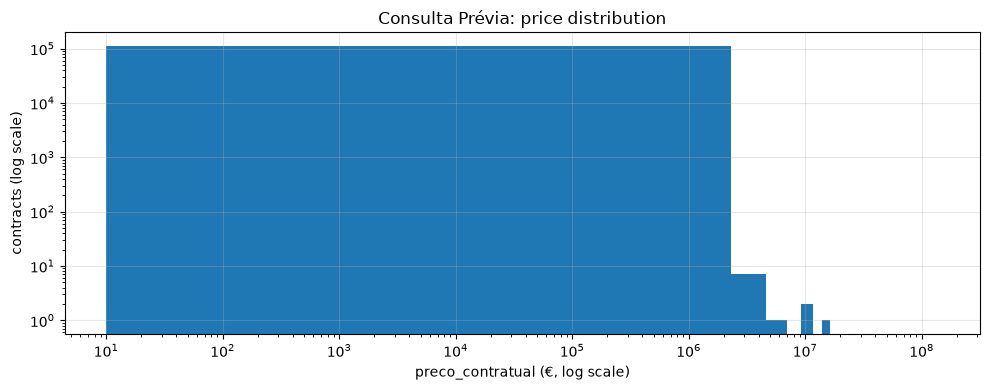

contracts above €5,000: 95,237
contracts above €20,000: 59,613
contracts above €75,000: 6,739


In [12]:
prices = proc["preco_contratual"].drop_nulls()
print(prices.describe())
fig, ax = plt.subplots()
ax.hist(prices.filter(prices > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("preco_contratual (€, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Consulta Prévia: price distribution")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
# Informal reference points only, not legal advice.
for t in (5_000, 20_000, 75_000):
    print(f"contracts above €{t:,}: {(prices > t).sum():,}")

concorrentes reported: 81.5%
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 91078.0  │
│ null_count ┆ 0.0      │
│ mean       ┆ 2.339632 │
│ std        ┆ 3.013333 │
│ min        ┆ 1.0      │
│ 25%        ┆ 1.0      │
│ 50%        ┆ 2.0      │
│ 75%        ┆ 3.0      │
│ max        ┆ 54.0     │
└────────────┴──────────┘


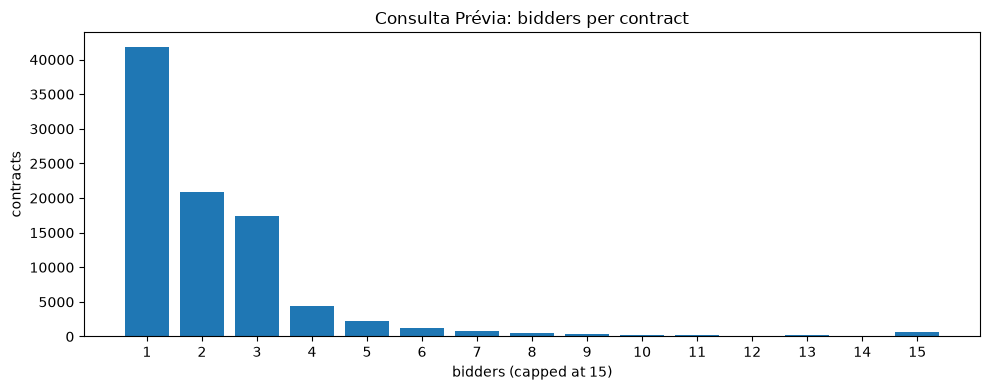

Single-bidder share among reported: 45.9%


tipo_criterio_adjudicacao,count
str,u32
"""Monofator""",101856
"""Multifator""",9730
null,93
"""Preço ou custo""",5
"""Melhor relação qualidade – pre…",2


tipo_procedimento,n_contracts,total_value,median_bidders
str,u32,f64,f64
"""Consulta Prévia""",110004,3.6980e9,2.0
"""Consulta Prévia Simplificada""",1652,2.7073e8,2.0
"""Consulta prévia ao abrigo do a…",30,3.7699e6,2.0


In [13]:
# Competition: `concorrentes` is a "\n"-separated list of "NIPC-name" bidders (null = not reported).
proc = proc.with_columns(
    pl.col("concorrentes").str.split("\n").list.eval(pl.element().str.strip_chars().filter(pl.element() != "")).list.len().alias("n_concorrentes")
)
print(f"concorrentes reported: {proc['concorrentes'].is_not_null().mean():.1%}")
print(proc["n_concorrentes"].drop_nulls().describe())
fig, ax = plt.subplots()
counts = proc["n_concorrentes"].drop_nulls().clip(upper_bound=15).value_counts().sort("n_concorrentes")
ax.bar(counts["n_concorrentes"].cast(pl.String), counts["count"])
ax.set_xlabel("bidders (capped at 15)")
ax.set_ylabel("contracts")
ax.set_title("Consulta Prévia: bidders per contract")
plt.tight_layout()
plt.show()
print("Single-bidder share among reported:", f"{(proc['n_concorrentes'] == 1).sum() / proc['n_concorrentes'].drop_nulls().len():.1%}")
display(proc["tipo_criterio_adjudicacao"].value_counts(sort=True))

# Sub-split by variant: standard vs simplified vs Lei 30/2021
display(proc.group_by("tipo_procedimento").agg(
    pl.len().alias("n_contracts"),
    pl.col("preco_contratual").sum().round(2).alias("total_value"),
    pl.col("n_concorrentes").median().alias("median_bidders"),
).sort("n_contracts", descending=True))

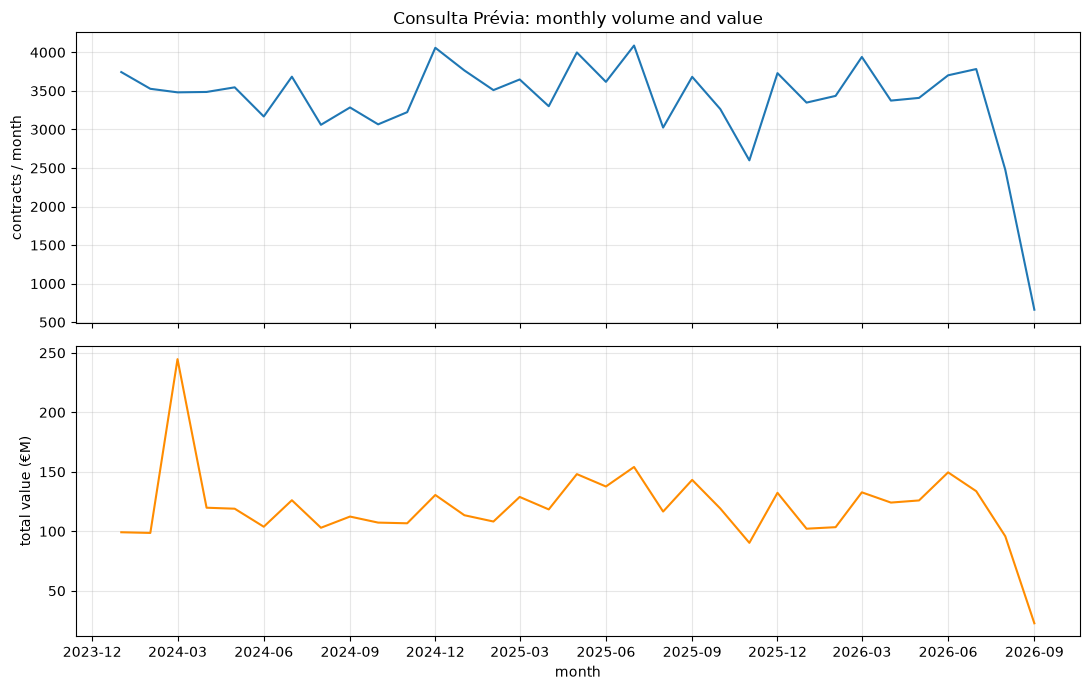

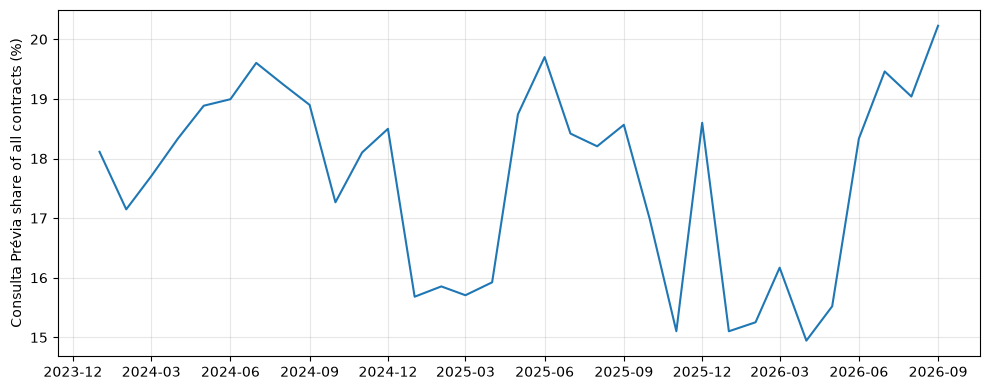

In [14]:
consulta_previa_monthly = (
    contracts.filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg(
        pl.len().alias("n_all"),
        CPREV_EXPR.sum().alias("n_contracts"),
        pl.col("preco_contratual").filter(CPREV_EXPR).sum().alias("total_value"),
    )
    .with_columns((pl.col("n_contracts") / pl.col("n_all")).alias("share"))
    .sort("month")
)
monthly = consulta_previa_monthly
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(monthly["month"], monthly["n_contracts"])
axes[0].set_ylabel("contracts / month")
axes[0].set_title("Consulta Prévia: monthly volume and value")
axes[1].plot(monthly["month"], monthly["total_value"] / 1e6, color="darkorange")
axes[1].set_ylabel("total value (€M)")
axes[1].set_xlabel("month")
for ax in axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.plot(consulta_previa_monthly["month"], consulta_previa_monthly["share"] * 100)
ax.set_ylabel("Consulta Prévia share of all contracts (%)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
proc.sort("preco_contratual", descending=True, nulls_last=True).select(
    "idcontrato", "adjudicante_name", "preco_contratual", "tipo_procedimento", "data_celebracao", "objecto_contrato"
).head(10)

idcontrato,adjudicante_name,preco_contratual,tipo_procedimento,data_celebracao,objecto_contrato
i64,str,f64,str,date,str
10617290,"""Infraestruturas de Portugal""",1.39e8,"""Consulta Prévia""",2024-03-13,"""FORNECIMENTO, INSTALAÇÃO, MONT…"
10757887,"""REN Atlântico - Terminal de GN…",1.4025e7,"""Consulta Prévia""",2024-04-01,"""PC-2023-000640 - Fornecimento…"
15338186,"""REN Atlântico - Terminal de GN…",1.0685e7,"""Consulta Prévia""",2026-04-01,"""PC-2025-000882 - Fornecimento …"
11180375,"""Município de Cascais""",1.0570e7,"""Consulta Prévia""",2025-01-21,"""Aquisição de serviços de vigil…"
11942460,"""REN - Serviços, S. A.""",4.7981e6,"""Consulta Prévia""",2025-03-21,"""PC-2024-000870 - Fornecimento …"
10835799,"""Infraestruturas de Portugal, S…",3.169e6,"""Consulta Prévia""",2024-07-24,"""IC2(EN1) - KM241+500 - RECONST…"
12049136,"""Companhia Carris de Ferro de L…",2.606064e6,"""Consulta Prévia""",2024-01-22,"""Serviços de vigilância"""
11361869,"""EMACOM - TELECOMUNICAÇÕES DA M…",2.6049e6,"""Consulta Prévia""",2025-03-20,"""Empreitada de obras de constru…"
11486867,"""Infraestruturas de Portugal""",2.5997e6,"""Consulta Prévia""",2025-06-05,"""Empreitada A21 - KM12+480. REP…"


## Commentary and limitations

- `Ano` covers 2025–2026 only; edge months of the monthly series are partial.
- Awardee value totals count a multi-awardee contract in full for each awardee.
- Entities are keyed by NIPC. Entries with the `-` (no NIF) sentinel are clustered by name similarity
  (`token_sort_ratio >= 92`) and may over- or under-merge; see `key_source`. Dirty NIPCs stay separate keys.
- Very large values may be outliers or data-entry errors.
- Consulta Prévia invites a limited set of firms, so `concorrentes` reflects invited/bidding firms as reported.
- Contracts with |value| below €10 (`MIN_VALUE`, applied to the absolute value) are disregarded; the before/after cell quantifies the effect.
- `valor_por_dia` = `preco_contratual / prazo_execucao`, only for 1–3650 days (0-day and >10-year values are treated as data errors). Short contracts inflate €/day.